# Phase 5: Walk-Forward Backtesting (จำลองการลงทุนจริงรายเดือน 7 ปี)

### คอนเซปต์ใหญ่ของโปรเจกต์นี้คืออะไร?
เรากำลัง **"จำลองการเป็นผู้จัดการกองทุนย้อนอดีตไป 7 ปี (2018–2024)"**:
1. **31 ธ.ค. 2017**: ผู้จัดการกองทุนนั่งดูข้อมูลสถิติหุ้นย้อนหลัง 3 ปี (2015–2017) เพื่อวิเคราะห์ Covariance แล้วตัดสินใจหาน้ำหนักหุ้นที่ดีที่สุด
2. **ม.ค. 2018**: ตลาดเปิด นำเงินไปซื้อหุ้นตามน้ำหนักนั้น ใช้สัดส่วนเป้าหมายเดิมเพื่อคำนวณผลตอบแทนรายวันตลอดเดือน ม.ค. แล้วดูว่าผลตอบแทนจริงแต่ละวันเป็นเท่าไหร่
3. **31 ม.ค. 2018**: สิ้นเดือน เลื่อนหน้าต่างข้อมูลมาเป็น (ก.พ. 2015 – ม.ค. 2018) ปรับพอร์ตใหม่สำหรับเดือน ก.พ. 2018
4. ทำซ้ำแบบนี้ทุกๆ สิ้นเดือนจนครบ **84 เดือน (7 ปีเต็ม)** โดยไม่มีการใช้ข้อมูลล่วงหน้า (No Look-ahead Bias) และคิดค่าธรรมเนียม 0.15% คูณด้วย turnover ทุกครั้งที่ปรับพอร์ต

## ตอนที่ 1: เตรียมข้อมูลและสร้างปฏิทิน Rebalance

### เซลล์ 1.1: โหลดราคาและแยก Benchmark ออกมา
- `load_price_matrix()`: ดึงตารางราคา Adjusted Close ของหุ้น 16 ตัวและ ETF 1 ตัว
- `prices["TDEX.BK"]`: ดึงราคาของ TDEX (SET50 ETF) แยกออกมาเป็น Benchmark วัดผล
- `prices.drop(columns=["TDEX.BK"])`: เหลือเฉพาะหุ้น 16 ตัวที่จะนำมาจัดพอร์ตแข่งขัน

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.data import DEFAULT_DB_PATH, load_price_matrix
from src.portfolio import (
    get_equal_weights,
    get_inverse_vol_weights,
    get_min_variance_weights,
    get_max_sharpe_weights
)
from src.risk import (
    calculate_annualized_return,
    calculate_annualized_volatility,
    calculate_sharpe_ratio,
    calculate_drawdowns,
    calculate_max_drawdown
)

# โหลดราคาปิดปรับปรุง
prices = load_price_matrix()
bench_prices = prices["TDEX.BK"]
stock_prices = prices.drop(columns=["TDEX.BK"])

print(f"จำนวนหุ้นที่จะจัดพอร์ต: {stock_prices.shape[1]} ตัว")
print(f"ชื่อหุ้น: {list(stock_prices.columns)}")
print(f"Benchmark อ้างอิง: TDEX.BK")
prices.head(2)

จำนวนหุ้นที่จะจัดพอร์ต: 16 ตัว
ชื่อหุ้น: ['ADVANC.BK', 'AOT.BK', 'BBL.BK', 'BDMS.BK', 'BH.BK', 'BJC.BK', 'CPALL.BK', 'CPN.BK', 'DELTA.BK', 'KBANK.BK', 'KTB.BK', 'MINT.BK', 'PTT.BK', 'PTTEP.BK', 'SCC.BK', 'TTB.BK']
Benchmark อ้างอิง: TDEX.BK
Out[0]: 
ticker       ADVANC.BK     AOT.BK  ...   TDEX.BK    TTB.BK
date                               ...                    
2015-01-05  141.822464  24.233814  ...  6.057407  1.556339
2015-01-06  140.683350  24.145048  ...  6.039342  1.534263

[2 rows x 17 columns]


### เซลล์ 1.2: แปลงราคาเป็น Daily Return และสร้างปฏิทินสิ้นเดือน
- `pct_change().dropna()`: คำนวณผลตอบแทนรายวัน $R_t = \frac{P_t - P_{t-1}}{P_{t-1}}$
- `resample("ME").last().index`: สร้างป้ายวันที่สิ้นเดือนตามปฏิทิน (Month-Ends) ตลอด 10 ปี (ได้ทั้งหมด 120 เดือน)
- `lookback_months = 36`: หน้าต่างดูข้อมูลย้อนหลัง 36 เดือน (3 ปี)
- `test_months = month_ends[36:]`: ช่วงเวลาทดสอบจริง 84 เดือน (ม.ค. 2018 ถึง ธ.ค. 2024)

In [2]:
# 1. คำนวณผลตอบแทนรายวัน
stock_returns = stock_prices.pct_change().dropna()
bench_returns = bench_prices.pct_change().dropna()

# 2. หาจุดสิ้นเดือน (Month-Ends)
month_ends = stock_returns.resample("ME").last().index
lookback_months = 36
test_months = month_ends[lookback_months:]

print("=== ตัวอย่างปฏิทินสิ้นเดือน (Month-Ends) 5 เดือนแรก ===")
for m in month_ends[:5]:
    print("->", m.strftime("%Y-%m-%d"))

print()
print(f"จำนวนเดือนทั้งหมด: {len(month_ends)} เดือน")
print(f"36 เดือนแรก (In-sample ก้อนแรก): {month_ends[0].strftime('%Y-%m-%d')} ถึง {month_ends[35].strftime('%Y-%m-%d')}")
print(f"84 เดือนที่เหลือ (ช่วงทดสอบจริง): {test_months[0].strftime('%Y-%m-%d')} ถึง {test_months[-1].strftime('%Y-%m-%d')}")


=== ตัวอย่างปฏิทินสิ้นเดือน (Month-Ends) 5 เดือนแรก ===
-> 2015-01-31
-> 2015-02-28
-> 2015-03-31
-> 2015-04-30
-> 2015-05-31

จำนวนเดือนทั้งหมด: 120 เดือน
36 เดือนแรก (In-sample ก้อนแรก): 2015-01-31 ถึง 2017-12-31
84 เดือนที่เหลือ (ช่วงทดสอบจริง): 2018-01-31 ถึง 2024-12-31


## ตอนที่ 2: สาธิตชำแหละการทำงานของ 1 เดือน (Toy Walkthrough: ม.ค. 2018)

เพื่อไม่ให้สับสน เราจะมาดูการทำงานทีละคำสั่งของ **รอบแรกสุด (i = 36 หรือเดือน มกราคม 2018)** กันแบบทีละเซลล์!

### เซลล์ 2.1: การหาวันที่และตัดช่วงข้อมูล (Time Slicing)

- ช่วงคำนวณน้ำหนักใช้ผลตอบแทนตั้งแต่ **1 ม.ค. 2015 ถึงสิ้น ธ.ค. 2017** ครบ 36 เดือนตามปฏิทิน
- ช่วงทดสอบใช้เงื่อนไข `(dates > train_end) & (dates <= test_month)` จึงเก็บ **3–31 ม.ค. 2018** รวม 21 วันซื้อขาย
- `train_end` คือวันสิ้นเดือนตามปฏิทิน ถึงวันนั้นเป็นวันหยุด เงื่อนไขวันที่ก็ยังเลือกวันซื้อขายแรกของเดือนใหม่ได้

In [3]:
def get_monthly_windows(returns, train_end, test_month, lookback_months):
    # ย้อนจากวันสิ้นเดือน เพื่อให้เก็บข้อมูลครบตั้งแต่ต้นเดือนแรก
    train_start = train_end - pd.offsets.MonthEnd(lookback_months)
    dates = returns.index
    in_train = (dates > train_start) & (dates <= train_end)
    in_test = (dates > train_end) & (dates <= test_month)
    return returns.loc[in_train], returns.loc[in_test]


i = lookback_months  # เดือนแรกที่มีข้อมูลย้อนหลังครบ 36 เดือน
train_end = month_ends[i - 1]
test_month = month_ends[i]
in_sample, out_sample = get_monthly_windows(
    stock_returns, train_end, test_month, lookback_months
)

print(f"วันสิ้นเดือนสำหรับคำนวณน้ำหนัก {train_end:%Y-%m-%d}")
print(f"วันซื้อขายในช่วงฝึก {in_sample.index[0]:%Y-%m-%d} ถึง {in_sample.index[-1]:%Y-%m-%d} ({len(in_sample)} วัน)")
print(f"วันซื้อขายในช่วงทดสอบ {out_sample.index[0]:%Y-%m-%d} ถึง {out_sample.index[-1]:%Y-%m-%d} ({len(out_sample)} วัน)")
print("ตัวอย่างผลตอบแทนรายหุ้นในช่วงทดสอบ (%)")
display((out_sample.head(3) * 100).round(2))

วันสิ้นเดือนสำหรับคำนวณน้ำหนัก 2017-12-31
วันซื้อขายในช่วงฝึก 2015-01-06 ถึง 2017-12-29 (729 วัน)
วันซื้อขายในช่วงทดสอบ 2018-01-03 ถึง 2018-01-31 (21 วัน)
ตัวอย่างผลตอบแทนรายหุ้นในช่วงทดสอบ (%)


ticker,ADVANC.BK,AOT.BK,BBL.BK,BDMS.BK,BH.BK,BJC.BK,CPALL.BK,CPN.BK,DELTA.BK,KBANK.BK,KTB.BK,MINT.BK,PTT.BK,PTTEP.BK,SCC.BK,TTB.BK
date,,,,,,,,,,,,,,,,
2018-01-03,2.88,3.68,1.49,0.48,1.59,-1.14,1.95,0.29,1.37,2.16,1.04,0.00,2.27,1.50,1.24,1.99
2018-01-04,-1.27,0.00,0.00,0.48,1.04,-1.53,0.00,-0.88,1.01,2.11,1.55,-3.43,4.89,4.43,1.22,0.00
2018-01-05,0.52,2.13,0.49,-0.95,-0.77,-0.39,-0.96,-1.77,0.67,-0.41,1.02,-2.37,-0.85,0.94,-1.21,-1.30


### เซลล์ 2.2: คำนวณหาน้ำหนักพอร์ต (Portfolio Optimization)
- เราส่ง `in_sample` (ข้อมูล 3 ปีย้อนหลัง) เข้าไปให้ฟังก์ชัน `get_min_variance_weights(in_sample)`
- โมเดลจะคำนวณ Covariance Matrix และหาน้ำหนัก $w_1, w_2, ..., w_{16}$ ที่ทำให้พอร์ตผันผวนต่ำที่สุด (โดยไม่แอบเห็นข้อมูลปี 2018 เลยแม้แต่วันเดียว)

In [4]:
# ส่ง in_sample ไปคำนวณหาน้ำหนัก
w_minvar = get_min_variance_weights(in_sample)

df_w = pd.DataFrame({"น้ำหนักพอร์ต Min-Var (%)": w_minvar * 100}).round(2)
print("=== น้ำหนักหุ้นแต่ละตัวที่โมเดลเลือกสำหรับเดือน ม.ค. 2018 ===")
display(df_w.sort_values(by="น้ำหนักพอร์ต Min-Var (%)", ascending=False))
print(f"ผลรวมน้ำหนักทั้งหมด: {w_minvar.sum():.2f} (ครบ 100% พอดี)")

=== น้ำหนักหุ้นแต่ละตัวที่โมเดลเลือกสำหรับเดือน ม.ค. 2018 ===
ผลรวมน้ำหนักทั้งหมด: 1.00 (ครบ 100% พอดี)


,น้ำหนักพอร์ต Min-Var (%)
ticker,
BDMS.BK,20.00
BBL.BK,18.62
SCC.BK,16.70
CPALL.BK,12.78
ADVANC.BK,7.31
AOT.BK,6.42
BJC.BK,5.83
DELTA.BK,5.01
TTB.BK,3.15


### เซลล์ 2.3: คำนวณ Turnover และหักค่าคอมมิชชั่น
- **Turnover คืออะไร?**: คือสัดส่วนการซื้อขายปรับพอร์ต
  - เดือนแรกสุด เราเริ่มจาก **เงินสด** (`prev_weights = 0`)
  - เราซื้อหุ้นจนเต็มพอร์ต 100% สัดส่วนการซื้อเข้าคือ 100% ส่วนสูตรในแบบจำลองนี้นับเฉพาะน้ำหนักหุ้นและให้ turnover เดือนแรก **50% (0.50)**
  - สูตร: $\text{Turnover} = 0.5 \times \sum |w_{\text{ใหม่}} - w_{\text{เก่า}}| = 0.5 \times 1.0 = 0.50$
- **Transaction Cost**: อัตรา 0.15% (15 bps)
  - ต้นทุนที่ต้องจ่าย = $0.50 \times 0.15\% = \mathbf{0.075\%}$

In [5]:
prev_w = np.zeros_like(w_minvar.values)  # เริ่มต้นจากเงินสด (0% ทุกตัว)
w = w_minvar.values

# 1. คำนวณผลรวมความต่างของน้ำหนัก
diff = np.abs(w - prev_w)
turnover = 0.5 * np.sum(diff)

# 2. คำนวณค่าคอมมิชชั่น
cost_rate = 0.0015  # 0.15% (ใช้ทั้งตัวอย่างและลูปหลัก)
cost = turnover * cost_rate

print(f"1. ผลรวมการเปลี่ยนน้ำหนัก sum(|w - prev_w|): {np.sum(diff):.4f}")
print(f"2. Turnover = 0.5 * {np.sum(diff):.4f} = {turnover:.4f} ({turnover*100:.1f}%)")
print(f"3. ค่าคอมมิชชั่นที่ต้องจ่าย = {turnover:.4f} x 0.15% = {cost:.6f} ({cost*100:.4f}%)")

1. ผลรวมการเปลี่ยนน้ำหนัก sum(|w - prev_w|): 1.0000
2. Turnover = 0.5 * 1.0000 = 0.5000 (50.0%)
3. ค่าคอมมิชชั่นที่ต้องจ่าย = 0.5000 x 0.15% = 0.000750 (0.0750%)


### เซลล์ 2.4: คำนวณผลตอบแทนรายวันและหักค่าธรรมเนียม

- `out_sample @ w` คูณผลตอบแทนรายหุ้นด้วยน้ำหนักเป้าหมายแล้วรวมเป็นผลตอบแทนพอร์ตในแต่ละวัน
- หักค่าธรรมเนียมเฉพาะวันซื้อขายแรกของเดือน ตารางแสดงทั้งก่อนหัก หลังหัก และ benchmark บนวันเดียวกัน

In [6]:
# 1. คำนวณผลตอบแทนพอร์ตก่อนหักค่าธรรมเนียม
gross_daily_ret = out_sample @ w
port_daily_ret = gross_daily_ret.copy()
ret_raw_day1 = port_daily_ret.iloc[0]

# 2. หักค่าธรรมเนียมในวันทำการแรก
port_daily_ret.iloc[0] -= cost
ret_net_day1 = port_daily_ret.iloc[0]

print(f"=== เปรียบเทียบผลตอบแทนวันแรก ({port_daily_ret.index[0]:%Y-%m-%d}) ===")
print(f"ก่อนหักค่าคอมฯ:  {ret_raw_day1*100:+.4f}%")
print(f"หักค่าคอมฯ:     -{cost*100:.4f}%")
print(f"สุทธิหลังหักคอมฯ: {ret_net_day1*100:+.4f}%")

# ตารางแสดงผลตอบแทน 5 วันแรกของเดือน ม.ค. 2018
df_show = pd.DataFrame({
    "พอร์ต Min-Var ก่อนหัก (%)": gross_daily_ret * 100,
    "พอร์ต Min-Var สุทธิ (%)": port_daily_ret * 100,
    "Benchmark TDEX (%)": bench_returns.loc[out_sample.index] * 100
}).round(4)
display(df_show.head(5))

=== เปรียบเทียบผลตอบแทนวันแรก (2018-01-03) ===
ก่อนหักค่าคอมฯ:  +1.3709%
หักค่าคอมฯ:     -0.0750%
สุทธิหลังหักคอมฯ: +1.2959%


,พอร์ต Min-Var ก่อนหัก (%),พอร์ต Min-Var สุทธิ (%),Benchmark TDEX (%)
date,,,
2018-01-03,1.3709,1.2959,1.8733
2018-01-04,0.1131,0.1131,1.0508
2018-01-05,-0.3462,-0.3462,0.1733
2018-01-08,0.0737,0.0737,-0.0865
2018-01-09,0.0152,0.0152,0.0866


### เซลล์ 2.5: การปรับพอร์ตเดือนถัดไป (ก.พ. 2018)

เลื่อนช่วงย้อนหลังไปหนึ่งเดือน แล้วเทียบน้ำหนักเป้าหมายของ ก.พ. กับ ม.ค. ตารางเรียงหุ้นจากส่วนต่างน้ำหนักมากไปน้อย และแสดง turnover กับค่าธรรมเนียมที่คำนวณได้

In [7]:
# เลื่อนไปเดือนที่ 37 (ก.พ. 2018)
i_feb = i + 1
in_sample_feb, _ = get_monthly_windows(
    stock_returns, month_ends[i_feb - 1], month_ends[i_feb], lookback_months
)
w_feb = get_min_variance_weights(in_sample_feb)

# เปรียบเทียบน้ำหนัก ม.ค. vs ก.พ.
df_reb = pd.DataFrame({
    "น้ำหนัก ม.ค. (%)": w_minvar * 100,
    "น้ำหนัก ก.พ. (%)": w_feb * 100,
    "ส่วนต่างซื้อขาย |w_กพ - w_มค| (%)": np.abs(w_feb - w_minvar) * 100
}).round(2)

turnover_feb = 0.5 * np.sum(np.abs(w_feb.values - w_minvar.values))
cost_feb = turnover_feb * cost_rate

print("=== ตารางเปรียบเทียบการปรับพอร์ตระหว่าง ม.ค. -> ก.พ. 2018 ===")
display(df_reb.sort_values(by="ส่วนต่างซื้อขาย |w_กพ - w_มค| (%)", ascending=False))
print(f"-> Turnover เดือน ก.พ. = 0.5 * sum(ส่วนต่าง) = {turnover_feb*100:.2f}%")
print(f"-> ค่าคอมมิชชั่นที่ถูกหัก = {turnover_feb*100:.2f}% x 0.15% = {cost_feb*100:.4f}%")

=== ตารางเปรียบเทียบการปรับพอร์ตระหว่าง ม.ค. -> ก.พ. 2018 ===
-> Turnover เดือน ก.พ. = 0.5 * sum(ส่วนต่าง) = 2.25%
-> ค่าคอมมิชชั่นที่ถูกหัก = 2.25% x 0.15% = 0.0034%


,น้ำหนัก ม.ค. (%),น้ำหนัก ก.พ. (%),ส่วนต่างซื้อขาย |w_กพ - w_มค| (%)
ticker,,,
SCC.BK,16.70,15.79,0.92
DELTA.BK,5.01,5.85,0.84
AOT.BK,6.42,6.98,0.56
MINT.BK,2.20,2.70,0.50
TTB.BK,3.15,2.65,0.50
BBL.BK,18.62,18.26,0.36
BJC.BK,5.83,6.03,0.20
CPALL.BK,12.78,12.58,0.20
ADVANC.BK,7.31,7.15,0.17


## ตอนที่ 3: Full Walk-Forward Engine (รันวนซ้ำอัตโนมัติ 84 เดือน)

เมื่อเข้าใจการทำงานของแต่ละบรรทัดในตอนที่ 2 แล้ว โค้ดด้านล่างนี้คือการนำตรรกะเดิมทั้งหมดมารวมใส่ใน `for loop` เพื่อรันอัตโนมัติ **84 เดือน (ม.ค. 2018 ถึง ธ.ค. 2024)** สำหรับทั้ง 4 กลยุทธ์ (`EW`, `IV`, `MinVar`, `MaxSharpe`) แข่งกับ `Benchmark (TDEX)`

In [8]:
# รายชื่อกลยุทธ์และตัวแปรเก็บผลลัพธ์
strategies = ["EW", "IV", "MinVar", "MaxSharpe"]
prev_weights = {s: np.zeros(stock_returns.shape[1]) for s in strategies}

daily_portfolio_returns = {s: [] for s in strategies}
daily_portfolio_returns["Benchmark"] = []
monthly_turnovers = {s: [] for s in strategies}
monthly_target_weights = []
gross_portfolio_returns = {s: [] for s in strategies}

print("กำลังรัน Walk-Forward Backtest 84 เดือน (2018-2024)...")

# ลูปเลื่อน Rolling Window ทีละ 1 เดือน ทั้งหมด 84 เดือน
for i in range(lookback_months, len(month_ends)):
    train_end = month_ends[i - 1]
    test_month = month_ends[i]

    # ใช้กติกาเดียวกับตัวอย่าง ม.ค. แล้วเลือก benchmark จากวันเดียวกัน
    in_sample, out_sample = get_monthly_windows(
        stock_returns, train_end, test_month, lookback_months
    )
    if out_sample.empty:
        continue
    bench_out = bench_returns.loc[out_sample.index]

    # 3. คำนวณหาน้ำหนักพอร์ตของแต่ละกลยุทธ์จาก In-sample Data
    weights = {
        "EW": get_equal_weights(in_sample).values,
        "IV": get_inverse_vol_weights(in_sample).values,
        "MinVar": get_min_variance_weights(in_sample).values,
        "MaxSharpe": get_max_sharpe_weights(in_sample).values
    }

    # เก็บน้ำหนักเป้าหมายชุดเดียวกับที่ใช้คำนวณผลตอบแทนเดือนนี้
    monthly_target_weights.append(
        pd.DataFrame(weights, index=out_sample.columns)
        .rename_axis("ticker")
        .reset_index()
        .melt(id_vars="ticker", var_name="strategy", value_name="weight")
        .assign(rebalance_date=out_sample.index[0])
    )

    # 4. คำนวณ Turnover, หักต้นทุนการเทรด และคำนวณผลตอบแทนรายวัน
    for s in strategies:
        w = weights[s]
        # สูตร Turnover = 0.5 * sum(|w_t - w_{t-1}|)
        turnover = 0.5 * np.sum(np.abs(w - prev_weights[s]))
        monthly_turnovers[s].append(turnover)

        cost = turnover * cost_rate
        prev_weights[s] = w

        # ผลตอบแทนของพอร์ตรายวัน = ผลคูณของผลตอบแทนรายหุ้นกับน้ำหนัก
        port_daily_ret = (out_sample @ w).copy()
        gross_portfolio_returns[s].append(port_daily_ret.copy())
        port_daily_ret.iloc[0] -= cost  # หักค่าคอมมิชชั่นวันแรกที่มีการ Rebalance
        daily_portfolio_returns[s].append(port_daily_ret)


    daily_portfolio_returns["Benchmark"].append(bench_out)

# รวมผลตอบแทนรายวันตลอด 7 ปี (2018-2024) เข้าเป็น DataFrame เดียว
backtest_returns = pd.DataFrame({
    s: pd.concat(daily_portfolio_returns[s]) for s in strategies + ["Benchmark"]
})

print("Backtest เสร็จสมบูรณ์!")
print(f"ช่วงเวลาทดสอบจริง: {backtest_returns.index[0].strftime('%Y-%m-%d')} ถึง {backtest_returns.index[-1].strftime('%Y-%m-%d')}")
print(f"จำนวนวันทำการทั้งหมด: {len(backtest_returns)} วันทำการ")
print(f"จำนวนเดือนที่เก็บผล gross และ net: {len(gross_portfolio_returns['EW'])} และ {len(daily_portfolio_returns['EW'])}")
print(f"จำนวนวันที่ซ้ำ: {backtest_returns.index.duplicated().sum()}")
print("ตัวอย่างผลตอบแทนสุทธิรายวัน (%)")
display((backtest_returns.head(3) * 100).round(4))

กำลังรัน Walk-Forward Backtest 84 เดือน (2018-2024)...
Backtest เสร็จสมบูรณ์!
ช่วงเวลาทดสอบจริง: 2018-01-03 ถึง 2024-12-30
จำนวนวันทำการทั้งหมด: 1700 วันทำการ
จำนวนเดือนที่เก็บผล gross และ net: 84 และ 84
จำนวนวันที่ซ้ำ: 0
ตัวอย่างผลตอบแทนสุทธิรายวัน (%)


,EW,IV,MinVar,MaxSharpe,Benchmark
date,,,,,
2018-01-03,1.3483,1.3667,1.2959,1.1998,1.8733
2018-01-04,0.6013,0.5620,0.1131,-0.2096,1.0508
2018-01-05,-0.3260,-0.3397,-0.3462,-0.4432,0.1733


## ตอนที่ 4: สรุปผลการดำเนินงานและเปรียบเทียบความเสี่ยง

1. **Annualized Return (%)**: $\bar{R}_{daily} \times 252$
2. **Annualized Volatility (%)**: $\sigma_{daily} \times \sqrt{252}$
3. **Sharpe Ratio (Rf=2.5%)**: $\frac{R_p - 0.025}{\sigma_p}$
4. **Max Drawdown (%)**: จุดขาดทุนลึกที่สุดที่พอร์ตเคยตกลงมาจากยอดดอย (Peak-to-Trough)
5. **Calmar Ratio**: $\frac{\text{Annual Return}}{|\text{Max Drawdown}|}$
6. **Annual Turnover (%)**: ปริมาณการซื้อขายเฉลี่ยต่อปี (Turnover รายเดือนเฉลี่ย $\times 12$)

- `Ann. Return` คือค่าเฉลี่ยผลตอบแทนรายวันคูณ 252 และใช้ในการคำนวณ Sharpe
- `CAGR` คืออัตราที่ทำให้เงินทบต้นถึงมูลค่าปลายทาง โดยประมาณจำนวนปีจากวันซื้อขายหาร 252
- `Calmar` ใช้ CAGR หารด้วยขนาดของ maximum drawdown

In [9]:
# 1. คำนวณตัวชี้วัด Risk & Return รายปี
ann_ret = calculate_annualized_return(backtest_returns) * 100
ann_vol = calculate_annualized_volatility(backtest_returns) * 100
sharpe = calculate_sharpe_ratio(backtest_returns, risk_free_rate=0.025)
mdd = calculate_max_drawdown(backtest_returns) * 100

# 2. คำนวณอัตราการหมุนพอร์ตเฉลี่ยต่อปี (Annualized Turnover)
ann_turnover = pd.Series({s: np.mean(monthly_turnovers[s]) * 12 * 100 for s in strategies})
ann_turnover["Benchmark"] = 0.0  # Benchmark ถือครองอย่างเดียว ไม่มีการ Rebalance

years = backtest_returns.count() / 252
cagr_pct = ((1 + backtest_returns).prod() ** (1 / years) - 1) * 100
calmar = cagr_pct / mdd.abs()

# 3. รวมเป็นตารางสรุปผลการดำเนินงานตลอด 7 ปี (Net of Costs)
summary_df = pd.DataFrame({
    "Ann. Return (%)": ann_ret,
    "CAGR (%)": cagr_pct,
    "Ann. Volatility (%)": ann_vol,
    "Sharpe Ratio (Rf=2.5%)": sharpe,
    "Max Drawdown (%)": mdd,
    "Calmar Ratio": calmar,
    "Ann. Turnover (%)": ann_turnover,
})

print("=== ตารางสรุปผล 7-Year Walk-Forward Backtest (2018–2024, Net of Costs) ===")
display(summary_df.round(2))

=== ตารางสรุปผล 7-Year Walk-Forward Backtest (2018–2024, Net of Costs) ===


,Ann. Return (%),CAGR (%),Ann. Volatility (%),Sharpe Ratio (Rf=2.5%),Max Drawdown (%),Calmar Ratio,Ann. Turnover (%)
EW,6.82,5.42,17.48,0.25,-44.02,0.12,7.14
IV,4.74,3.37,16.84,0.13,-43.56,0.08,13.72
MinVar,3.51,2.38,15.17,0.07,-40.59,0.06,49.75
MaxSharpe,12.09,10.72,19.50,0.49,-38.93,0.28,122.70
Benchmark,2.80,1.63,15.37,0.02,-36.53,0.04,0.00


In [10]:
ew = backtest_returns["EW"].dropna()
ending_value = (1 + ew).prod()
ew_years = len(ew) / 252
ew_cagr = ending_value ** (1 / ew_years) - 1

print(f"เงิน 1 บาทโตเป็น {ending_value:.2f} บาท")
print(f"EW CAGR: {ew_cagr:.2%} | ผลตอบแทนเฉลี่ยรายปี: {ann_ret['EW']:.2f}%")


เงิน 1 บาทโตเป็น 1.43 บาท
EW CAGR: 5.42% | ผลตอบแทนเฉลี่ยรายปี: 6.82%


In [11]:
gross_returns = pd.DataFrame({
    s: pd.concat(months) for s, months in gross_portfolio_returns.items()
})
gross_years = gross_returns.count() / 252
gross_cagr_pct = ((1 + gross_returns).prod() ** (1 / gross_years) - 1) * 100

cost_comparison = pd.DataFrame({
    "Gross CAGR (%)": gross_cagr_pct,
    "Net CAGR (%)": cagr_pct.loc[gross_returns.columns],
})
cost_comparison["CAGR Difference (pp)"] = (
    cost_comparison["Gross CAGR (%)"] - cost_comparison["Net CAGR (%)"]
)

print("เปรียบเทียบ CAGR ก่อนและหลังหักค่าธรรมเนียม")
print("ส่วนต่างวัดเป็นจุดเปอร์เซ็นต์ (pp)")
display(cost_comparison.round(4))

เปรียบเทียบ CAGR ก่อนและหลังหักค่าธรรมเนียม
ส่วนต่างวัดเป็นจุดเปอร์เซ็นต์ (pp)


,Gross CAGR (%),Net CAGR (%),CAGR Difference (pp)
EW,5.4318,5.4202,0.0116
IV,3.3879,3.3660,0.0219
MinVar,2.4564,2.3772,0.0792
MaxSharpe,10.9356,10.7242,0.2114


## ตอนที่ 5: พล็อตการเติบโตของพอร์ต (Equity Curves) และกราฟติดดอย (Drawdown)

- `cum_returns = (1 + backtest_returns).cumprod()`: แปลงผลตอบแทนรายวันเป็น **Wealth Index** (สมมติเริ่มลงทุน 1 บาท โตเป็นกี่บาท)
- `drawdowns = calculate_drawdowns(backtest_returns) * 100`: คำนวณเปอร์เซ็นต์ติดดอยสะสมข้ามเวลา

เงินปลายทางต่อเงินเริ่มต้น 1 บาท (หลังหักค่าธรรมเนียม)


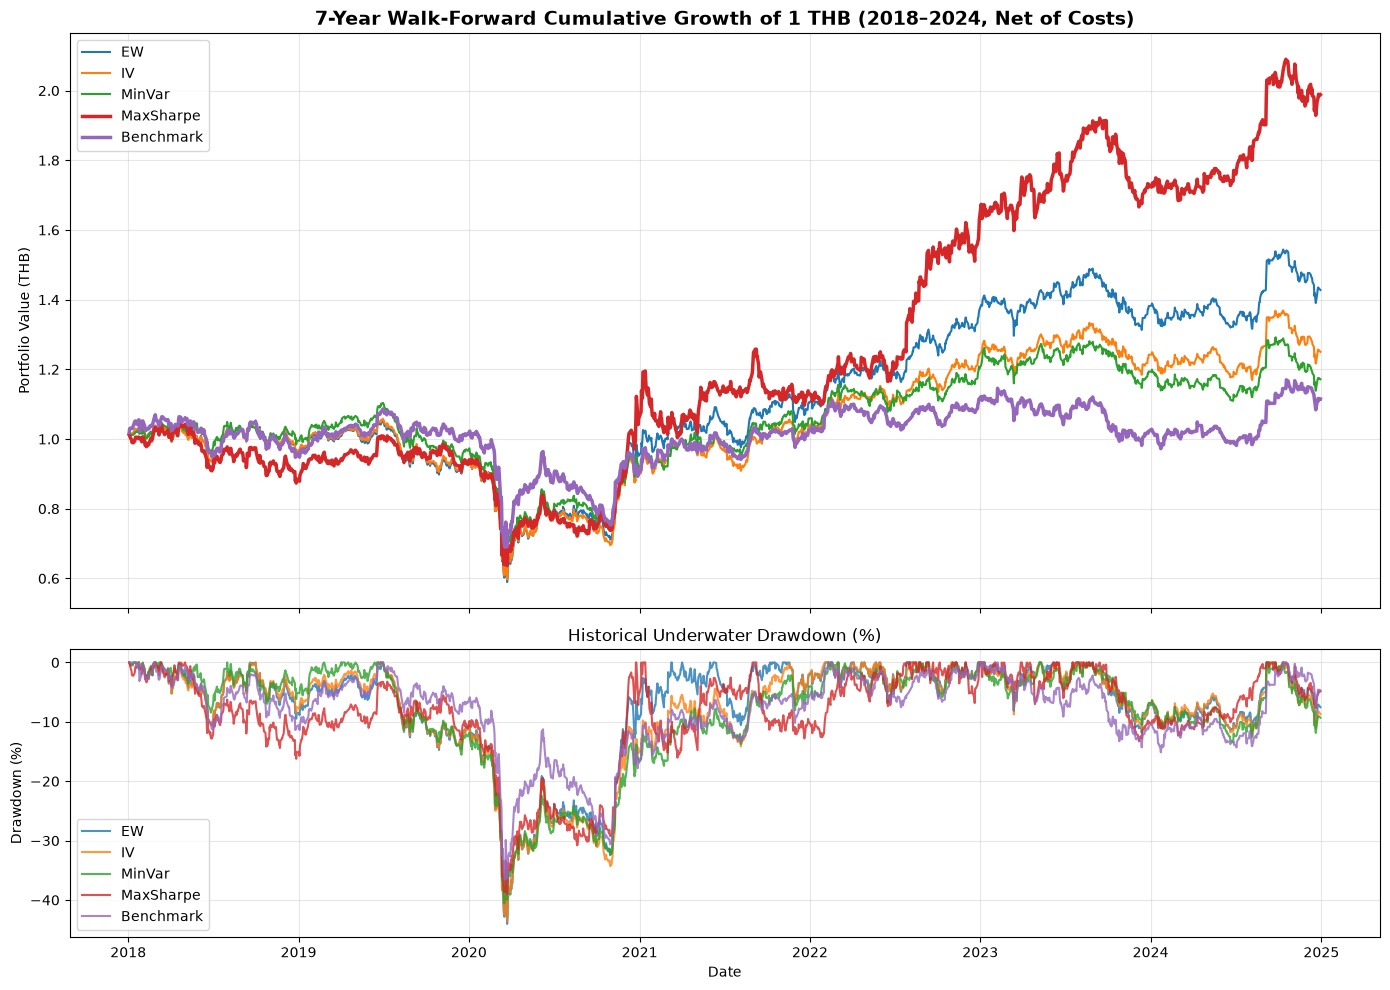

,มูลค่าพอร์ต (บาท)
EW,1.428
IV,1.250
MinVar,1.172
MaxSharpe,1.988
Benchmark,1.115


In [12]:
# 1. คำนวณ Wealth Index และ Drawdown
cum_returns = (1 + backtest_returns).cumprod()
drawdowns = calculate_drawdowns(backtest_returns) * 100

# 2. วาดกราฟ 2 หน้าต่าง (แผงบน: มูลค่าพอร์ต, แผงล่าง: Underwater Drawdown)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

# แผงบน: เส้นการเติบโตสะสมของเงิน 1 บาท (Equity Curve)
for col in cum_returns.columns:
    lw = 2.5 if col in ["MaxSharpe", "Benchmark"] else 1.5
    ax1.plot(cum_returns.index, cum_returns[col], label=col, linewidth=lw)
ax1.set_title("7-Year Walk-Forward Cumulative Growth of 1 THB (2018–2024, Net of Costs)", fontsize=14, fontweight="bold")
ax1.set_ylabel("Portfolio Value (THB)")
ax1.grid(True, alpha=0.3)
ax1.legend(loc="upper left")

# แผงล่าง: กราฟ Underwater Drawdown (%)
for col in drawdowns.columns:
    ax2.plot(drawdowns.index, drawdowns[col], label=col, alpha=0.8)
ax2.set_title("Historical Underwater Drawdown (%)", fontsize=12)
ax2.set_ylabel("Drawdown (%)")
ax2.set_xlabel("Date")
ax2.grid(True, alpha=0.3)
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

print("เงินปลายทางต่อเงินเริ่มต้น 1 บาท (หลังหักค่าธรรมเนียม)")
display(cum_returns.iloc[-1].rename("มูลค่าพอร์ต (บาท)").round(3).to_frame())

### วิธีอ่านผลและสมมติฐาน

- Benchmark คือ **TDEX.BK (SET50 ETF)** ผลที่สรุปเทียบกับ ETF ตัวนี้
- พอร์ตใช้สัดส่วนเป้าหมายเดิมในการคำนวณผลตอบแทนทุกวันในเดือน ส่วน turnover ใช้ส่วนต่างระหว่างน้ำหนักเป้าหมายรายเดือน สูตรนี้เป็นแบบจำลองที่ยังไม่ได้ติดตามน้ำหนักที่เปลี่ยนตามราคาจริงระหว่างเดือน
- รายชื่อหุ้นเป็นชุดคงที่ตลอดช่วงทดสอบ ผลจึงอาจได้รับผลจาก survivorship bias และควรอ่านร่วมกับสมมติฐานค่าธรรมเนียม

## ตอนที่ 6: ส่งออกผลลัพธ์ Phase 5

`backtest_summary.csv` เก็บตัวชี้วัดของ 4 พอร์ตและ benchmark ส่วน `equity_curves.csv` เก็บมูลค่าสะสมรายวันของเงินเริ่มต้น 1 บาท คอลัมน์ Gross CAGR ของ benchmark เว้นว่าง เพราะแบบจำลองค่าธรรมเนียมใช้กับกลยุทธ์จัดพอร์ต

In [13]:
output_dir = DEFAULT_DB_PATH.parents[1] / "outputs"
output_dir.mkdir(exist_ok=True)

summary_export = summary_df.rename(columns={"CAGR (%)": "Net CAGR (%)"})
summary_export = summary_export.join(cost_comparison[["Gross CAGR (%)", "CAGR Difference (pp)"]])

summary_path = output_dir / "backtest_summary.csv"
equity_path = output_dir / "equity_curves.csv"
summary_export.round(4).to_csv(summary_path, index_label="strategy")
cum_returns.to_csv(equity_path, index_label="date")

print(f"บันทึก {summary_path.name} — {len(summary_export)} แถว")
print(f"บันทึก {equity_path.name} — {len(cum_returns):,} แถว")
print(f"ช่วงข้อมูล {cum_returns.index[0]:%Y-%m-%d} ถึง {cum_returns.index[-1]:%Y-%m-%d}")
print(f"โฟลเดอร์ {output_dir}")

บันทึก backtest_summary.csv — 5 แถว
บันทึก equity_curves.csv — 1,700 แถว
ช่วงข้อมูล 2018-01-03 ถึง 2024-12-30
โฟลเดอร์ /Users/tim/gemini_vscode/Carreer_path/CV_round2/ttb_T00013266/Thai_Equity_Portfolio/outputs


In [14]:
# อ่าน CSV ที่เพิ่ง export กลับมาเพื่อดูข้อมูลในไฟล์จริง
summary_csv = pd.read_csv(summary_path)
equity_csv = pd.read_csv(equity_path)

print(f"{summary_path.name} — สรุปผลครบ {len(summary_csv)} แถว")
display(summary_csv)

print(f"{equity_path.name} — {len(equity_csv):,} แถว | แสดง 5 วันแรก")
display(equity_csv.head())
print("5 วันสุดท้าย")
display(equity_csv.tail())

backtest_summary.csv — สรุปผลครบ 5 แถว


,strategy,Ann. Return (%),Net CAGR (%),Ann. Volatility (%),Sharpe Ratio (Rf=2.5%),Max Drawdown (%),Calmar Ratio,Ann. Turnover (%),Gross CAGR (%),CAGR Difference (pp)
0,EW,6.8183,5.4202,17.4839,0.2470,-44.0221,0.1231,7.1429,5.4318,0.0116
1,IV,4.7389,3.3660,16.8397,0.1330,-43.5603,0.0773,13.7233,3.3879,0.0219
2,MinVar,3.5069,2.3772,15.1660,0.0664,-40.5881,0.0586,49.7482,2.4564,0.0792
3,MaxSharpe,12.0924,10.7242,19.5001,0.4919,-38.9321,0.2755,122.6965,10.9356,0.2114
4,Benchmark,2.8005,1.6281,15.3652,0.0196,-36.5327,0.0446,0.0000,NaN,NaN


equity_curves.csv — 1,700 แถว | แสดง 5 วันแรก


,date,EW,IV,MinVar,MaxSharpe,Benchmark
0,2018-01-03,1.013483,1.013667,1.012959,1.011998,1.018733
1,2018-01-04,1.019577,1.019364,1.014105,1.009877,1.029438
2,2018-01-05,1.016254,1.015901,1.010594,1.005401,1.031222
3,2018-01-08,1.014075,1.014664,1.011339,0.997344,1.030330
4,2018-01-09,1.015296,1.016013,1.011493,0.990559,1.031222


5 วันสุดท้าย


,date,EW,IV,MinVar,MaxSharpe,Benchmark
1695,2024-12-24,1.428292,1.251085,1.171832,1.974165,1.110118
1696,2024-12-25,1.435113,1.257038,1.175114,1.980429,1.116355
1697,2024-12-26,1.431887,1.253806,1.173206,1.989703,1.110118
1698,2024-12-27,1.431958,1.254103,1.174635,1.984718,1.116355
1699,2024-12-30,1.427725,1.250236,1.171744,1.988209,1.115108


## ตอนที่ 7: ส่งออกน้ำหนักสำหรับหน้า Holdings

`holdings_weights.csv` เก็บน้ำหนักเป้าหมายที่ backtest ใช้จริง หนึ่งแถวต่อเดือน กลยุทธ์ และหุ้น โดย `rebalance_date` คือวันซื้อขายแรกของเดือนที่ใช้น้ำหนักชุดนั้น และ `weight_pct` อยู่ในหน่วยเปอร์เซ็นต์ เช่น 6.25 หมายถึง 6.25% ของพอร์ต

ใน Power BI เลือกทีละกลยุทธ์เพื่อดูสัดส่วนหุ้นของพอร์ตตามเวลา ไฟล์นี้เก็บทั้ง 4 กลยุทธ์และรวมแถวของหุ้นที่มีน้ำหนักศูนย์ ส่วน TDEX เป็น ETF ที่ใช้เทียบผลตอบแทน เราจึงไม่มีน้ำหนักเป้าหมายรายหุ้นจาก backtest สำหรับ TDEX

In [15]:
holdings = pd.concat(monthly_target_weights, ignore_index=True)
holdings["weight_pct"] = (holdings["weight"] * 100).round(8)
holdings = holdings[["rebalance_date", "strategy", "ticker", "weight_pct"]]

holdings_path = DEFAULT_DB_PATH.parents[1] / "outputs" / "holdings_weights.csv"
holdings_path.parent.mkdir(exist_ok=True)
holdings.to_csv(holdings_path, index=False, date_format="%Y-%m-%d")

holdings_csv = pd.read_csv(holdings_path, parse_dates=["rebalance_date"])
print(f"บันทึก outputs/{holdings_path.name} — {len(holdings_csv):,} แถว")
print(f"{holdings_csv['rebalance_date'].nunique()} เดือน × {holdings_csv['strategy'].nunique()} กลยุทธ์ × {holdings_csv['ticker'].nunique()} หุ้น")
print("ตัวอย่างน้ำหนักหุ้นรายตัวจากเดือนแรก")
display(holdings_csv.head(5))
print("ตัวอย่างผลรวมน้ำหนักของแต่ละกลยุทธ์ในเดือนแรก (%)")
first_month = holdings_csv.loc[holdings_csv["rebalance_date"].eq(holdings_csv["rebalance_date"].min())]
display(first_month.groupby("strategy")["weight_pct"].sum().round(6).to_frame())

บันทึก outputs/holdings_weights.csv — 5,376 แถว
84 เดือน × 4 กลยุทธ์ × 16 หุ้น
ตัวอย่างน้ำหนักหุ้นรายตัวจากเดือนแรก


,rebalance_date,strategy,ticker,weight_pct
0,2018-01-03,EW,ADVANC.BK,6.25
1,2018-01-03,EW,AOT.BK,6.25
2,2018-01-03,EW,BBL.BK,6.25
3,2018-01-03,EW,BDMS.BK,6.25
4,2018-01-03,EW,BH.BK,6.25


ตัวอย่างผลรวมน้ำหนักของแต่ละกลยุทธ์ในเดือนแรก (%)


,weight_pct
strategy,
EW,100.0
IV,100.0
MaxSharpe,100.0
MinVar,100.0
